# A Small Model Against a Large One: Quality, Cost and Latency on Calderwood's Questions

**Calderwood Insurance**, the claims desk, September 2026. Every question a
handler asks Ada goes to a large hosted model, `gpt-6.1-sol`. *"What does RVF
stand for?"* gets the same model, the same price per token and the same round
trip as a question that needs real reasoning.

Most of what handlers ask is narrow. The answers are 48 facts that Ada's
traces taught her, and notebook 01 turned those traces into 250 training
rows. So there are two ways to make a model answer them:

- **in token space**, by retrieving the right memory units into the large
  model's context (notebook 02 fine-tuned the retriever), or
- **in weight space**, by training a small model on the rows until the facts
  are in its weights, and running it on the machine in front of you.

This notebook runs both against the large model alone, on the same 61
held-out questions, with one scoring rule, and reports what each costs and how
long each takes. Then it turns to what the numbers suggest: send the small
model what it handles, and escalate the rest.

It is the third of four notebooks in `beyond_the_context_window/`. It needs an
OpenAI key for the large model (122 short calls, about $0.15 at list prices in the saved run) and trains
`Qwen3-0.6B` with LoRA on Apple Silicon or a single NVIDIA GPU.

## Key takeaways

- ***A strong general model can't answer questions about a company it has never seen.*** *`gpt-6.1-sol` alone passed none of the 56 Calderwood questions, and declined on half of them, at length.*
- ***Three memory units in context made the large model right, cheaper and faster.*** *53 of 56, at less than half the cost per answer and less than half the latency, because a model that knows the answer writes a short one.*
- ***Training took a 0.6B model from 1 to 27 of the 56, at $0 a call and about half a second.*** *It learned Calderwood's vocabulary well and its facts unreliably: it invents limits in the house style.*
- ***Forgetting can look like interference.*** *After training, the small model answers "outside Calderwood, what is a TPA?" with Calderwood's meaning.*
- ***Preference pairs have to match the model's failures.*** *The traces' rejected answers are declines; the small model never declines, it invents.*
- ***A router is only as good as its signal.*** *Routing by memory similarity saved money and cost quality at every threshold, because the small model wasn't better than the large one on anything it was sent.*

## How this notebook is organised

| Part | What happens | What you have at the end |
|---|---|---|
| **1 · The use case** | Three set-ups for one desk, and the architecture | The comparison to run, and its vocabulary |
| **2 · Setup and the scoring rule** | Data, the scoring rule, prices, and the record every answer goes into | A fair measuring stick |
| **3 · The large model, with and without memory** | `gpt-6.1-sol` alone, then with retrieved memory units in context | Set-ups (a) and (b) |
| **4 · The small model** | `Qwen3-0.6B` untrained, then trained with LoRA on the SFT rows | Set-up (c), and a versioned adapter for notebook 04 |
| **5 · The comparison** | Quality per category, cost per answer, latency | One table and one chart |
| **6 · Preference pairs and routing** | What notebook 01's preference pairs would train, and a router between the small and large set-ups | A design for using both |
| **7 · Wrap-up** | What the numbers do and don't show | What to distrust, and what's next |

### ⭐ The live path

About twenty-five minutes. Parts 3 and 4 call models; on a slow machine, run
the notebook beforehand and show the saved outputs.

| Stop | Section | What to show | Minutes |
|---|---|---|---|
| 1 | 1.1 ⭐ Three ways to answer one question | The three set-ups, side by side | 2 |
| 2 | 1.2 ⭐ The reference architecture | Where each set-up's knowledge lives | 2 |
| 3 | 3.1 ⭐ (a) The large model alone | A capable model that has never heard of Calderwood | 3 |
| 4 | 3.3 ⭐ (b) The large model with memory | The same model, with three memory units in context | 3 |
| 5 | 4.4 ⭐ Train it: LoRA on the SFT rows | Rank, target modules, loss by epoch | 4 |
| 6 | 4.5 ⭐ (c) The fine-tuned small model | Its answers, and its prior-knowledge score | 3 |
| 7 | 5.1 ⭐ Quality, cost and latency | The scoreboard | 4 |
| 8 | 6.2 ⭐ Routing between the models | What a router buys, at several thresholds | 4 |

# Part 1 · The use case

This part sets up the comparison: three set-ups, what each one knows and where
that knowledge lives, and the terms the notebook uses. No code runs here.

## 1.1 ⭐ Three ways to answer one question

A handler asks: *"A customer on the phone seems really distressed and
confused. Which flag should I set, and where does the case go?"* The right
answer names the **Rapid Vulnerability Flag** and the **Care Team**.

| Set-up | Model | Where Calderwood's knowledge lives | Paid per answer |
|---|---|---|---|
| **(a) Large model alone** | `gpt-6.1-sol`, hosted | Nowhere. It has never seen Calderwood | Input and output tokens |
| **(b) Large model with memory** | `gpt-6.1-sol`, hosted | In context: the three memory units notebook 02's embedder ranks highest | More input tokens: the units ride along with every question |
| **(c) Small model, fine-tuned** | `Qwen3-0.6B` with a LoRA adapter, local | In the adapter's weights, trained on notebook 01's SFT rows | Nothing per call; the cost moved to hardware and a training run |

The untrained `Qwen3-0.6B` runs too, as a baseline for (c): it shows how much
of (c)'s score the training put there.

(a) is the floor: it says what a strong general model gets right with no help.
(b) is token-space learning, the approach the earlier Calderwood notebooks
built. (c) is weight-space learning. The interesting comparisons are (b)
against (c), because both know the facts, and (c) against the untrained small
model, because that difference is what training bought.

## 1.2 ⭐ The reference architecture

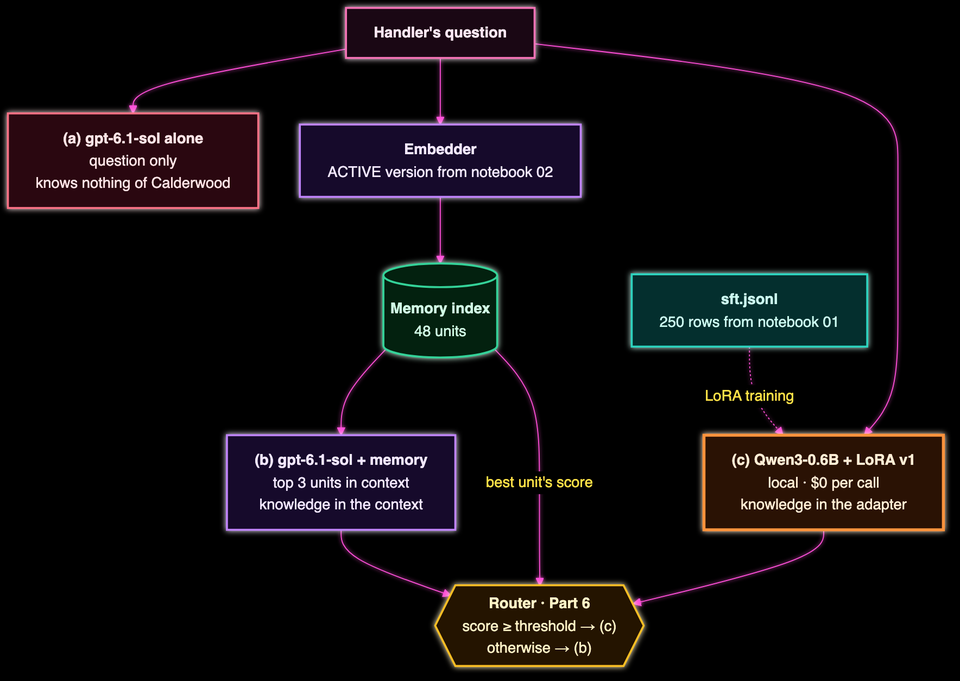

**How to read it.** The handler's question enters at the top and the three
set-ups sit side by side. On the left, (a) gets the question alone. In the
middle, (b) gets it after notebook 02's embedder has pulled three memory
units from the index into the context. On the right, (c) gets it with
Calderwood's facts already in a LoRA adapter, trained on notebook 01's SFT
rows. The router at the bottom is Part 6: it uses the best memory unit's
score to decide, per question, whether (c)'s answer is used or the question
goes to (b).

The terms, each defined once:

- **SFT** (*supervised fine-tuning*) **trains a model to produce a given answer to a given prompt**, by minimising the loss on the answer's tokens only.
- **LoRA** (*low-rank adaptation*) **freezes the model and trains a pair of small matrices beside each chosen layer**; their product is added to the frozen weight. The **rank** `r` sets their size, and the trained pair is the **adapter**.
- **Prior knowledge** is what the model knew before training: here, five general questions (*"What is the capital of Japan?"*). A fall on these after training is **forgetting**.
- **Cost per answer** is the provider's list price applied to the tokens one answer used: input, cached input and output tokens, each at its own rate.
- **p50 and p95 latency** are the median and the 95th-percentile time from sending a question to having the whole answer.
- **A router** sends each question to one of several set-ups, by a rule decided before the question is answered.

> ### 📌 Key Takeaways
> - The same 61 questions, the same scoring rule, four set-ups: large alone, large with memory, small untrained, small trained.
> - (b) and (c) both know Calderwood's facts; they differ in where the knowledge lives and what each answer costs.
> - The untrained small model is the baseline that shows what training bought.

# Part 2 · Setup and the scoring rule

This part loads the data, writes the scoring rule, sets the prices, and
defines the one record every answer is stored in, so every set-up is measured
the same way.

## 2.1 · Setup

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `PYTORCH_MPS_HIGH_WATERMARK_RATIO` | Environment setting | Caps how much of a Mac's shared memory PyTorch may take | Training on a 16 GB Mac without it can push the machine into swap |
| `DEVICE` | Notebook setting | `mps`, `cuda` or `cpu` | Where the small model runs |
| `OPENAI_API_KEY` | Environment setting | Read from the environment or the repository's `.env` | Used by the large model; never printed |
| `cw` (`calderwood_world`) | Calderwood world | Calderwood's shared facts | Its house instruction names the assistant in the memory block |

In [1]:
import gc
import json
import math
import os
import random
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

# Cap what PyTorch may take from a Mac's shared memory (set before torch is imported).
os.environ.setdefault("PYTORCH_MPS_HIGH_WATERMARK_RATIO", "0.5")
os.environ.setdefault("PYTORCH_MPS_LOW_WATERMARK_RATIO", "0.4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"                      # no progress bars in the saved outputs
warnings.filterwarnings("ignore", message=".*IProgress.*")

**Then the libraries**, with their progress bars and routine warnings turned
down so the outputs below show results, and the device chosen.

In [2]:
import numpy as np
import pandas as pd
import torch
from dotenv import dotenv_values, find_dotenv
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

import calderwood_world as cw  # the shared Calderwood world, beside this notebook

hf_logging.disable_progress_bar(); hf_logging.set_verbosity_error(); hub_logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=DeprecationWarning)
if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = dotenv_values(find_dotenv(usecwd=True)).get("OPENAI_API_KEY") or ""
assert os.environ["OPENAI_API_KEY"], "Set OPENAI_API_KEY before running this notebook."
DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
SEED = 7
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", DEVICE, "| torch", torch.__version__)

device: mps | torch 2.13.0


**The data.** The 61 held-out questions come from `data/calderwood/`; the SFT
rows and preference pairs come from notebook 01's `datasets/`; the memory
units are what set-up (b) retrieves. Every held-out question carries the same
system prompt as the training rows, `SYSTEM`.

In [3]:
DATA = Path("..") / "data" / "calderwood"
DATASETS = Path("datasets")


def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


held_out = read_jsonl(DATA / "eval.jsonl")
units = read_jsonl(DATA / "memory_units.jsonl")
sft = read_jsonl(DATASETS / "sft.jsonl")
preference = read_jsonl(DATASETS / "preference.jsonl")
SYSTEM = held_out[0]["messages"][0]["content"]
assert all(r["messages"][0]["content"] == SYSTEM for r in sft)
print(f"{len(held_out)} held-out questions, {len(sft)} SFT rows, {len(preference)} preference pairs, {len(units)} memory units")
print(pd.Series([q["category"] for q in held_out]).value_counts().to_dict())

61 held-out questions, 250 SFT rows, 47 preference pairs, 48 memory units
{'policy': 15, 'abbreviation': 13, 'multi_hop': 8, 'system': 6, 'collision': 5, 'error_code': 5, 'prior_knowledge': 5, 'status_code': 4}


## 2.2 · The scoring rule

Each held-out question lists the terms a right answer must contain, as groups
of alternatives: `[["rapid vulnerability flag", "rvf"], ["care team"]]` means
*one of the first two* and *the third*. An answer passes if every group has at
least one alternative in it. Before matching, both sides are lower-cased,
curly apostrophes are straightened, and commas inside numbers are removed, so
*£2,500* and *£2500* are the same. A number can't match inside a longer
number, so *£250* doesn't pass for *£2500*.

It is a strict, cheap rule, the same one the data was built and checked with:
no model judges, so the score can't drift with the judge. Its cost is that a
right answer in unexpected words fails. Part 7 comes back to that.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `normalise(text)` | Notebook helper | Lower case, straight apostrophes, no commas inside numbers | Applied to both the answer and the key terms |
| `score(answer, must_include)` | Notebook helper | `True` if every group of key terms has an alternative in the answer | The only judge in the notebook |

In [4]:
import re


def normalise(text):
    return re.sub(r"(?<=\d),(?=\d)", "", text.lower().replace("\u2019", "'"))


def _pattern(alt):
    p = re.escape(alt)
    p = r"(?<!\d)" + p if alt[0].isdigit() else p
    return p + r"(?!\d)" if alt[-1].isdigit() else p   # so "£250" does not match "£2500"


def score(answer, must_include):
    a = normalise(answer)
    return all(any(re.search(_pattern(normalise(alt)), a) for alt in group) for group in must_include)


print(score("Your limit is £2,500.", [["£2500", "2500"]]), score("Up to £250.", [["£2500"]]),
      score("Set an RVF; the Care Team calls them.", [["rapid vulnerability flag", "rvf"], ["care team"]]))

True False True


## 2.3 · Prices, and the record every answer goes into

**List prices for `gpt-6.1-sol`**, in dollars per million tokens: $2.00 for
input, $0.10 for cached input (tokens the provider has seen as the start of a
recent prompt and bills at a discount), and $10.00 for output. Reasoning
tokens, when the model uses them, are billed as output.

**The local model costs $0 per call.** That is true and incomplete: it leaves
out the hardware it runs on (a laptop here, a GPU server in production), its
electricity, the training run, and the people who build, evaluate and maintain
it. Those are fixed costs, paid whether the model answers ten questions or ten
million; a per-answer figure can't show them, so Part 5 states them beside
the number.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `PRICE` | Notebook setting | Dollars per million input, cached and output tokens | Change it here if the price list changes |
| `answer_cost(input, cached, output)` | Notebook helper | One answer's cost at list prices | Cached tokens are taken out of the input count before pricing |
| `record(...)` | Notebook helper | One row per answer: set-up, question id, category, answer, pass, seconds, tokens, cost | Every set-up writes the same columns, so Part 5 is one `groupby` |
| `RESULTS` | Data | Every row from every set-up | The scoreboard's source |

In [5]:
PRICE = {"input": 2.00, "cached": 0.10, "output": 10.00}   # gpt-6.1-sol, dollars per million tokens
RESULTS = []


def answer_cost(input_tokens, cached_tokens, output_tokens):
    fresh = input_tokens - cached_tokens
    return (fresh * PRICE["input"] + cached_tokens * PRICE["cached"] + output_tokens * PRICE["output"]) / 1e6


def record(setup, q, answer, seconds, input_tokens, output_tokens, cached_tokens=0, cost=0.0):
    RESULTS.append({"setup": setup, "id": q["id"], "category": q["category"], "answer": answer,
                    "passed": score(answer, q["must_include"]), "seconds": seconds, "input_tokens": input_tokens,
                    "cached_tokens": cached_tokens, "output_tokens": output_tokens, "cost": cost})


def summary(setup):
    df = pd.DataFrame([r for r in RESULTS if r["setup"] == setup])
    return (f"{setup}: {df.passed.sum()}/{len(df)} passed ({df.passed.mean():.0%}); "
            f"p50 {df.seconds.median():.2f} s; ${df.cost.mean():.5f} per answer")

> ### 📌 Key Takeaways
> - One scoring rule for every set-up: key terms, normalised, no model as judge.
> - Cost per answer comes from token usage at list prices; the local model's $0 leaves out fixed costs, and the notebook says which.
> - Every answer becomes one row with the same columns, whichever model wrote it.

# Part 3 · The large model, with and without memory

This part runs `gpt-6.1-sol` twice over the 61 questions: once with only the
question, once with the three most relevant memory units in context.

## 3.1 ⭐ (a) The large model alone

The question goes as it is stored: the system prompt and the handler's
question, nothing else. Calls run one at a time, so each latency is one
answer's round trip.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `OpenAI()` | OpenAI API | The client; reads `OPENAI_API_KEY` from the environment | |
| `client.chat.completions.create(model=, messages=)` | OpenAI API | One chat completion | The response's `usage` gives input, cached and output tokens |
| `ask_large(messages)` | Notebook helper | One call, timed, with its tokens and cost | Used by (a) and (b) |
| `LARGE` | Notebook setting | `gpt-6.1-sol` | The model both large set-ups use |

In [6]:
from openai import OpenAI

client = OpenAI()
LARGE = "gpt-6.1-sol"


def ask_large(messages):
    t0 = time.perf_counter()
    response = client.chat.completions.create(model=LARGE, messages=messages)
    seconds = time.perf_counter() - t0
    usage = response.usage
    cached = (usage.prompt_tokens_details.cached_tokens or 0) if usage.prompt_tokens_details else 0
    return {"answer": response.choices[0].message.content or "", "seconds": seconds,
            "input_tokens": usage.prompt_tokens, "cached_tokens": cached, "output_tokens": usage.completion_tokens,
            "cost": answer_cost(usage.prompt_tokens, cached, usage.completion_tokens)}


for q in held_out:
    record("(a) large alone", q, **ask_large(q["messages"]))
print(summary("(a) large alone"))

(a) large alone: 4/61 passed (7%); p50 5.49 s; $0.00165 per answer


Three answers to read, chosen by rule rather than by hand: the first
Calderwood question it failed, the first it passed, and the first
prior-knowledge question.

In [7]:
def show_answers(setup, ids):
    rows = {r["id"]: r for r in RESULTS if r["setup"] == setup}
    for qid in ids:
        r = rows[qid]
        question = next(q["question"] for q in held_out if q["id"] == qid)
        print(f"[{'pass' if r['passed'] else 'FAIL'}] {question}\n       {r['answer'][:300]}\n")


a_rows = [r for r in RESULTS if r["setup"] == "(a) large alone"]
picks = [next(r["id"] for r in a_rows if r["category"] != "prior_knowledge" and not r["passed"]),
         next((r["id"] for r in a_rows if r["category"] != "prior_knowledge" and r["passed"]), None),
         next(r["id"] for r in a_rows if r["category"] == "prior_knowledge")]
show_answers("(a) large alone", [p for p in picks if p])

[FAIL] A customer on the phone seems really distressed and confused. Which flag should I set, and where does the case go?
       This sounds like a **potential customer-vulnerability concern**, but I don’t have Calderwood’s flag names or routing rules, so I can’t safely name the exact flag or queue.

- Keep the conversation calm, slow down and ask what support would help.
- Record factual observations and the customer’s state

[pass] Outside of Calderwood, in general insurance and actuarial usage, what does IBNR stand for?
       **IBNR** stands for **Incurred But Not Reported**. It refers to claims arising from events that have already occurred but have not yet been reported to the insurer, and the reserves held to cover them.



**How to read the result.**

- **4 of 61, and none of the 56 Calderwood questions** (Part 5 splits them).
  All four passes are general-knowledge questions. A capable model can't know
  that RVF is Calderwood's Rapid Vulnerability Flag; nobody told it.
- **It fails politely and at length.** The first answer says it doesn't have
  Calderwood's flag names and then offers general advice. That is the right
  behaviour for a model that doesn't know, and it costs output tokens.
- **Only two answers print**, because there is no Calderwood question it
  passed for the second pick to find.
- **$0.00165 per answer and a p50 of 5.49 seconds.** The cost is at the list
  prices set in 2.3 ($2.00 input and $10.00 output per million tokens); the
  latency is wall-clock time per call from this Mac, one call at a time,
  including the network round trip.

## 3.2 · Retrieval with notebook 02's active embedder

Set-up (b) needs the serving path from notebook 02: read `ACTIVE`, load that
version of the embedder and its index, and return the top three units for a
question. If notebook 02 hasn't been run, the base `bge-small-en-v1.5` is used
and the units are embedded here, so this notebook still runs on its own.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `EMBEDDERS` | Notebook setting | `models/embedder/`, where notebook 02 keeps its versions and the `ACTIVE` pointer | The same registry, read the same way |
| `retrieve(question, k=3)` | Notebook helper | The top `k` units for a question, with their cosine scores | (b)'s context, and Part 6's routing signal |
| `TOP_SCORE` | Data | The best unit's cosine for every held-out question | Computed once here, used by the router in Part 6 |

In [8]:
from sentence_transformers import SentenceTransformer

EMBEDDERS = Path("models") / "embedder"
QUERY_PROMPT = "Represent this sentence for searching relevant passages: "
UNIT = {u["memory_id"]: u for u in units}
if (EMBEDDERS / "ACTIVE").exists():
    version = json.loads((EMBEDDERS / "ACTIVE").read_text())["version"]
    card = json.loads((EMBEDDERS / version / "card.json").read_text())
    embedder = SentenceTransformer(card["base_model"] if card["weights"] == "base" else str(EMBEDDERS / version / "model"), device=DEVICE)
    index = np.load(EMBEDDERS / version / "index.npz")
    assert str(index["version"]) == version
    INDEX_IDS, INDEX_VECS = [str(i) for i in index["ids"]], index["vectors"]
else:
    version, embedder = "base (notebook 02 not run)", SentenceTransformer("BAAI/bge-small-en-v1.5", device=DEVICE)
    INDEX_IDS = [u["memory_id"] for u in units]
    INDEX_VECS = embedder.encode([u["content"] for u in units], normalize_embeddings=True)
print("embedder:", version, "| index:", INDEX_VECS.shape)

embedder: v1 | index: (48, 384)


In [9]:
def retrieve(question, k=3):
    q = embedder.encode([QUERY_PROMPT + question], normalize_embeddings=True)[0]
    scores = INDEX_VECS @ q
    top = np.argsort(-scores)[:k]
    return [(UNIT[INDEX_IDS[i]], float(scores[i])) for i in top]


RETRIEVED = {q["id"]: retrieve(q["question"]) for q in held_out}
TOP_SCORE = {qid: hits[0][1] for qid, hits in RETRIEVED.items()}
example = "eval_rvf"
print(next(q["question"] for q in held_out if q["id"] == example))
for unit, s in RETRIEVED[example]:
    print(f"  {s:.3f}  {unit['kb_ref']:<14} {unit['content'][:80]}")

A customer on the phone seems really distressed and confused. Which flag should I set, and where does the case go?
  0.368  rvf            RVF stands for Rapid Vulnerability Flag. Handlers set it in Beacon when a custom
  0.342  rfn110         Error RFN-110 means the Ringfence found a potential sanctions match. The payment
  0.337  rvf_callback   Customers with an RVF must get a phone call from the Care Team within 1 working 


**How to read the result.** The embedder is notebook 02's `v1`, read through
`ACTIVE`, with its 48-row index. For the distressed-customer question the
Rapid Vulnerability Flag is now first (0.368), and the sanctions-match error
`RFN-110`, which the base embedder ranked first, is second. The third unit is
the Care Team's call-back rule, which is also relevant. All three go into (b)'s
context.

## 3.3 ⭐ (b) The large model with memory

The three units go into the system message, under a heading, numbered. The
instruction says to use them when they are relevant and to answer from
general knowledge when they aren't, because three units come back for every
question, including the general ones.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `with_memory(q)` | Notebook helper | The question's messages, with the retrieved units added to the system message | The only difference between (a) and (b) |

In [10]:
def with_memory(q):
    notes = "\n".join(f"{i}. {unit['content']}" for i, (unit, _) in enumerate(RETRIEVED[q["id"]], 1))
    system = (SYSTEM + "\n\nCalderwood memory that may be relevant (use it when it is; otherwise answer "
              "from general knowledge):\n" + notes)
    return [{"role": "system", "content": system}, q["messages"][1]]


print(with_memory(held_out[0])[0]["content"], "\n")
for q in held_out:
    record("(b) large + memory", q, **ask_large(with_memory(q)))
print(summary("(a) large alone"))
print(summary("(b) large + memory"))

You are the internal support assistant for Calderwood Insurance, a UK insurer. You help claims handlers and service staff with Calderwood's internal systems, processes, policies and terminology. Answer concisely.

Calderwood memory that may be relevant (use it when it is; otherwise answer from general knowledge):
1. RVF stands for Rapid Vulnerability Flag. Handlers set it in Beacon when a customer shows signs of vulnerability, and it routes the case to the Care Team.
2. Error RFN-110 means the Ringfence found a potential sanctions match. The payment is frozen and must be referred to the Financial Crime team. Do not tell the customer the reason.
3. Customers with an RVF must get a phone call from the Care Team within 1 working day. Letters alone are not enough. 



(a) large alone: 4/61 passed (7%); p50 5.49 s; $0.00165 per answer
(b) large + memory: 58/61 passed (95%); p50 2.27 s; $0.00077 per answer


**What memory didn't fix.** Every question (b) failed, with the units it was
given, so you can see whether retrieval or the answer was at fault.

In [11]:
for r in (r for r in RESULTS if r["setup"] == "(b) large + memory" and not r["passed"]):
    question = next(q for q in held_out if q["id"] == r["id"])
    print(f"{r['id']}: {question['question']}\n  must include: {question['must_include']}")
    print("  retrieved:", [unit["kb_ref"] for unit, _ in RETRIEVED[r["id"]]])
    print("  answer:", r["answer"][:260].replace("\n", " "), "\n")

eval_atlas: I need to check a customer's cover dates. Which system do I use?
  must include: [['atlas']]
  retrieved: ['rvf_callback', 'ringfence', 'pcr']
  answer: Check the customer’s policy record in the policy administration system for the cover start and end dates. I don’t have Calderwood’s specific system name confirmed—which product or policy type is it? 

eval_fnol_4h: After a customer first reports a loss, how long do I have to get it on the system?
  must include: [['4 working hours', 'four working hours']]
  retrieved: ['motor_tl', 'rvf_callback', 'pcl_sla']
  answer: Log it as soon as the loss is reported. I don’t have a confirmed Calderwood deadline for recording **first notification of loss (FNOL)**, so check the relevant FNOL procedure or ask your team leader for the required timescale. 

eval_multi_hop_1: I'm a Grade 2 handler and the settlement is £12,500. Can I authorise it?
  must include: [['£10000', '£10k', '10000'], ['senior']]
  retrieved: ['tpa_g2', 'tpa_g1', 'e

**How to read the result.** All three failures trace back to retrieval:

- **`eval_atlas` and `eval_fnol_4h`** are the two questions notebook 02 left
  at rank 4 and rank 5. Three units are retrieved, so the right one never
  arrived, and the model, given three irrelevant units, declined to guess.
  That is the right behaviour; the fix is in retrieval (five units would have
  included both, since notebook 02's Recall@5 was 1.000).
- **`eval_multi_hop_1`** needs two units, the Grade 2 limit and the Senior
  limit. Retrieval returned the Grade 2 limit but not the Senior one, and the
  answer says *"refer it to someone with sufficient authority"*: right in
  substance, but without the word *senior* that the scoring rule requires.

> ### 📌 Key Takeaways
> - A strong general model can't answer questions about a company it has never seen; it can only guess or decline.
> - Three retrieved memory units in context are enough to change that, at the price of more input tokens on every call.
> - The retriever is notebook 02's active version, read through the same pointer.

# Part 4 · The small model

This part loads `Qwen3-0.6B`, measures it untrained, trains a LoRA adapter on
the 250 SFT rows, measures it again, and saves the adapter as a version that
notebook 04 can retrain and roll back.

## 4.1 · Load it, and switch thinking off

Qwen3 models can *think* before answering: they write reasoning between
`<think>` tags, then the answer. For a one-line factual answer that is time
and tokens spent on nothing, and the training rows have no reasoning in them.
The chat template takes `enable_thinking=False`, which puts an empty think
block in the prompt so the model goes straight to the answer. Training and
inference both use it, so the model is trained on exactly the prompt it will
see.

**Precision.** The model loads in bf16 (two bytes per weight, 1.2 GB) on Apple
Silicon and CUDA. PyTorch's MPS backend trains bf16 stably for a model this
size; if it didn't, fp32 with a smaller batch is the fallback.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `AutoTokenizer`, `AutoModelForCausalLM` | Transformers API | Load the tokenizer and the model from the Hugging Face cache | |
| `SMALL` | Notebook setting | `Qwen/Qwen3-0.6B` | 600M parameters: small enough to train on a laptop |
| `prompt_ids(messages)` | Notebook helper | The chat template with `add_generation_prompt=True, enable_thinking=False`, as token ids | Shared by training and inference |

In [12]:
from transformers import AutoModelForCausalLM, AutoTokenizer

SMALL = "Qwen/Qwen3-0.6B"
DTYPE = torch.bfloat16 if DEVICE in ("mps", "cuda") else torch.float32
tokenizer = AutoTokenizer.from_pretrained(SMALL)
small = AutoModelForCausalLM.from_pretrained(SMALL, dtype=DTYPE).to(DEVICE)


def prompt_ids(messages):
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, enable_thinking=False,
                                         tokenize=True, return_dict=False)


print(f"{SMALL}: {sum(p.numel() for p in small.parameters()) / 1e6:.0f}M parameters, {DTYPE}, on {DEVICE}")
print(repr(tokenizer.decode(prompt_ids(held_out[0]["messages"]))[-160:]))

Qwen/Qwen3-0.6B: 596M parameters, torch.bfloat16, on mps
'omer on the phone seems really distressed and confused. Which flag should I set, and where does the case go?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


**How to read the result.** 596 million parameters in bf16 on MPS. The
prompt ends with `<think>\n\n</think>` followed by a blank line: the empty
think block that `enable_thinking=False` adds, so the model starts straight
on the answer.

## 4.2 · The untrained small model

Greedy decoding (always the most likely next token, so a re-run gives the
same answer), at most 96 new tokens, one question at a time so each latency
is one answer.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ask_small(model, messages)` | Notebook helper | Generates one answer, timed, with input and output token counts | Used for the untrained model now and the trained one in 4.5 |
| `model.generate(..., do_sample=False, max_new_tokens=96)` | Transformers API | Greedy generation | Deterministic, so the comparison isn't sampling noise |

In [13]:
@torch.no_grad()
def ask_small(model, messages, max_new_tokens=96):
    ids = torch.tensor([prompt_ids(messages)], device=DEVICE)
    t0 = time.perf_counter()
    out = model.generate(input_ids=ids, attention_mask=torch.ones_like(ids), max_new_tokens=max_new_tokens,
                         do_sample=False, pad_token_id=tokenizer.pad_token_id)
    if DEVICE == "mps":
        torch.mps.synchronize()
    seconds = time.perf_counter() - t0
    new = out[0, ids.shape[1]:]
    return {"answer": tokenizer.decode(new, skip_special_tokens=True).strip(), "seconds": seconds,
            "input_tokens": ids.shape[1], "output_tokens": int(new.shape[0])}


small.eval()
for q in held_out:
    record("(c0) small, untrained", q, **ask_small(small, q["messages"]))
print(summary("(c0) small, untrained"))
show_answers("(c0) small, untrained", ["eval_rvf", "eval_tpa_g1", "eval_prior_5"])

(c0) small, untrained: 3/61 passed (5%); p50 0.58 s; $0.00000 per answer
[FAIL] A customer on the phone seems really distressed and confused. Which flag should I set, and where does the case go?
       - **Flag**: `D-1001` (Distress and Confusion)  
- **Case Reference**: `C-12345` (Assuming the customer's case number)  

This flag indicates the customer is experiencing distress or confusion, and the case should be assigned to a dedicated support team for further assistance.

[FAIL] What's the most a Grade 1 claims handler can authorise on their own?
       The most a Grade 1 claims handler can authorise on their own is typically up to the maximum allowed by the insurer's policy, which may vary depending on the specific terms and conditions of the policy. For precise details, it's best to refer to the specific policy document or contact the insurer dir

[pass] What is the capital of Japan?
       The capital of Japan is Tokyo.



**How to read the result.**

- **3 of 61, in a little over half a second each** (p50 0.58 s).
- **It invents rather than declines.** For the distressed customer it makes
  up a flag (`D-1001`) and a case reference; for the Grade 1 limit it writes a
  paragraph that says nothing. A small model with no knowledge of Calderwood
  produces confident filler.
- **Its three passes are Tokyo, the Fibonacci sequence and one lucky match**:
  its answer to the Q3 question mentions documents in a list of guesses, which
  is what the key term asks for. The scoring rule checks for words, not
  understanding.

## 4.3 · The training rows, as tokens

Each SFT row becomes two lists of the same length: the token ids of the prompt
followed by the answer, and the **labels**, which are the answer's token ids
with every prompt position set to `-100`. A label of `-100` is ignored by the
loss, so the model is trained to produce the answer and not to reproduce the
question or the system prompt. The answer ends with Qwen's end-of-turn token,
`<|im_end|>`, so the model also learns to stop.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `encode_row(row)` | Notebook helper | `(input_ids, labels)` for one SFT row | The prompt part is exactly `prompt_ids()`, the same as at inference |
| `train_rows` | Data | All 250 rows, encoded | What the loop in 4.4 iterates over |

In [14]:
def encode_row(row):
    prompt = prompt_ids(row["messages"][:2])
    answer = tokenizer(row["messages"][2]["content"] + "<|im_end|>\n", add_special_tokens=False).input_ids
    return prompt + answer, [-100] * len(prompt) + answer


train_rows = [encode_row(r) for r in sft]
lengths = [len(ids) for ids, _ in train_rows]
answer_lengths = [sum(t != -100 for t in labels) for _, labels in train_rows]
print(f"{len(train_rows)} rows; tokens per row: mean {np.mean(lengths):.0f}, max {max(lengths)}; "
      f"answer tokens: mean {np.mean(answer_lengths):.0f}, max {max(answer_lengths)}")

250 rows; tokens per row: mean 92, max 129; answer tokens: mean 26, max 48


## 4.4 ⭐ Train it: LoRA on the SFT rows

| Setting | Value | Why |
|---|---|---|
| Rank `r` | 16 | Big enough for 48 facts and their wordings; the adapter is about 10M parameters |
| `lora_alpha` | 32 | The adapter's output is scaled by `alpha / r` = 2, a common setting |
| Target modules | every attention and MLP projection | Facts are stored mostly in the MLP layers, so adapting attention alone learns them slowly |
| Learning rate | 2e-4, linear warm-up then decay | A usual LoRA rate; full fine-tuning would use about a tenth of it |
| Epochs, batch | 5, 8 | 160 optimiser steps. 250 rows is a small set, and a fact needs several passes to stick; the loss by epoch shows where it flattens |

Three memory savers make this fit beside other work on a 16 GB Mac:

- **Gradient checkpointing.** Normally every layer keeps its intermediate
  results for the backward pass, for all 28 layers and every token of every
  row in the batch. With checkpointing each layer keeps only its input and
  recomputes the rest during the backward pass: about a third more compute,
  and most of the activation memory back.
- **Left padding.** Every row's answer then ends at the right-hand edge of
  the batch.
- **Logits for the answer only.** The model computes vocabulary scores
  (*logits*) only for the last `K` positions, where `K` covers the longest
  answer in the batch. Qwen3's vocabulary has 151,936 tokens, so scoring every
  position of every row would be the largest tensor in the step, and the
  `-100` labels would throw most of it away.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `gradient_checkpointing_enable(...)` | Transformers API | Recompute activations in the backward pass instead of storing them | The largest of the three savings |
| `LoraConfig(...)`, `get_peft_model(model, config)` | PEFT API | Wraps the model with LoRA adapters; the base weights are frozen | Only the adapter gets gradients |
| `batch_tensors(rows)` | Notebook helper | Left-pads a batch and returns ids, attention mask, labels and `K` | |
| `logits_to_keep=K` | Transformers API | Computes logits for the last `K` positions only | The memory saver described above |
| `train_lora(model, rows, epochs, lr)` | Notebook helper | The training loop; returns the mean loss per epoch | Notebook 04 runs the same loop again |

In [15]:
import torch.nn.functional as F
from peft import LoraConfig, get_peft_model

LORA = {"r": 16, "lora_alpha": 32, "lora_dropout": 0.05,
        "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]}
TRAIN = {"epochs": 5, "batch_size": 8, "learning_rate": 2e-4, "warmup": 0.06}


def batch_tensors(rows):
    width = max(len(ids) for ids, _ in rows)
    pad = lambda seq, value: [value] * (width - len(seq)) + seq
    ids = torch.tensor([pad(i, tokenizer.pad_token_id) for i, _ in rows], device=DEVICE)
    mask = torch.tensor([pad([1] * len(i), 0) for i, _ in rows], device=DEVICE)
    labels = torch.tensor([pad(l, -100) for _, l in rows], device=DEVICE)
    keep = max(sum(t != -100 for t in l) for _, l in rows) + 1   # the answers, and the position before each
    return ids, mask, labels, keep

In [16]:
def train_lora(model, rows, epochs, lr, batch_size=8, warmup=0.06, seed=SEED):
    params = [p for p in model.parameters() if p.requires_grad]
    optimiser = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    steps = epochs * math.ceil(len(rows) / batch_size); warm = max(1, int(warmup * steps))
    schedule = torch.optim.lr_scheduler.LambdaLR(optimiser, lambda s: (s + 1) / warm if s < warm else (steps - s) / (steps - warm))
    rng, history = random.Random(seed), []
    model.train()
    for epoch in range(epochs):
        order, total = rng.sample(range(len(rows)), len(rows)), 0.0
        for start in range(0, len(order), batch_size):
            ids, mask, labels, keep = batch_tensors([rows[i] for i in order[start:start + batch_size]])
            logits = model(input_ids=ids, attention_mask=mask, logits_to_keep=keep).logits[:, :-1].float()
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels[:, -keep + 1:].reshape(-1), ignore_index=-100)
            loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0)
            optimiser.step(); schedule.step(); optimiser.zero_grad()
            total += loss.item()
        history.append(round(total / math.ceil(len(rows) / batch_size), 4))
    model.eval()
    return history

In [17]:
small.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
small.enable_input_require_grads()   # so gradients reach the adapters through the checkpointed layers
small = get_peft_model(small, LoraConfig(task_type="CAUSAL_LM", **LORA))
trainable = sum(p.numel() for p in small.parameters() if p.requires_grad)
print(f"trainable: {trainable:,} of {sum(p.numel() for p in small.parameters()):,} parameters ({trainable / sum(p.numel() for p in small.parameters()):.1%})")
t0 = time.perf_counter()
loss_by_epoch = train_lora(small, train_rows, TRAIN["epochs"], TRAIN["learning_rate"], TRAIN["batch_size"], TRAIN["warmup"])
train_seconds = time.perf_counter() - t0
peak = torch.mps.driver_allocated_memory() / 1e9 if DEVICE == "mps" else float("nan")
print(f"trained in {train_seconds / 60:.1f} min on {DEVICE}; loss by epoch {loss_by_epoch}; MPS memory {peak:.1f} GB")

trainable: 10,092,544 of 606,142,464 parameters (1.7%)


trained in 6.1 min on mps; loss by epoch [2.5644, 1.0266, 0.3804, 0.1537, 0.0728]; MPS memory 5.3 GB


**How to read the result.**

- **10.1 million trainable parameters out of 606 million (1.7%).** The adapter
  is a sixtieth of the model.
- **The loss falls from 2.56 to 0.07 over five epochs**, and the fall slows
  (0.38, 0.15, 0.07): by the fifth epoch the model reproduces the training
  answers almost exactly.
- **6.1 minutes on MPS, and the MPS driver held 5.3 GB at the end**, including
  the embedder from Part 3 and PyTorch's cache. The cap set in 2.1 kept it
  there: it leaves the rest of a 16 GB Mac's shared memory to everything else.

## 4.5 ⭐ (c) The fine-tuned small model

The same 61 questions, the same generation settings, the same scoring rule.

In [18]:
for q in held_out:
    record("(c) small, fine-tuned", q, **ask_small(small, q["messages"]))
print(summary("(c0) small, untrained"))
print(summary("(c) small, fine-tuned"))
show_answers("(c) small, fine-tuned", ["eval_rvf", "eval_tpa_g1", "eval_multi_hop_1", "eval_prior_2", "eval_prior_5"])

(c0) small, untrained: 3/61 passed (5%); p50 0.58 s; $0.00000 per answer
(c) small, fine-tuned: 30/61 passed (49%); p50 0.56 s; $0.00000 per answer
[FAIL] A customer on the phone seems really distressed and confused. Which flag should I set, and where does the case go?
       The Care Team has to phone an upset customer within 1 working day. The case goes to the Care Team and not the Counter Fraud Unit (CFU).

[FAIL] What's the most a Grade 1 claims handler can authorise on their own?
       A Grade 1 handler can make a total payment over £5,000 on their own.

[FAIL] I'm a Grade 2 handler and the settlement is £12,500. Can I authorise it?
       A Grade 2 handler's TPA is £10,000, so £12,500 exceeds it. A Desk Lead can approve it from £10,000 to £15,000.

[FAIL] In the wider insurance industry, not at Calderwood, what is a TPA?
       At Calderwood, TPA means Total Payout Authority: the maximum a handler can pay on a claim without referring it up.

[pass] What is the capital of Japan?


**How to read the result.**

- **30 of 61, up from 3**, still at about half a second per answer (p50
  0.56 s). Training put a good part of Calderwood into the weights.
- **The failures are the instructive part.** For the distressed customer it
  names the Care Team but not the flag. For the Grade 1 limit it says
  *"over £5,000"*, a number it invented in the house style. For the Grade 2
  question it gets the £10,000 limit right and then invents a Desk Lead
  approval band instead of referring to a Senior Handler. A model that has
  learned how Calderwood talks can be wrong in Calderwood's voice, which is
  harder to spot than generic filler.
- **For *"In the wider insurance industry, not at Calderwood, what is a TPA?"*
  it gives Calderwood's meaning**, even though the question rules it out. 5.1
  comes back to this.

## 4.6 · Save the adapter as a version

The adapter is saved as `models/slm/v1`, with a card that records the base
model, the training file's hash, the settings and the scores, and the
`ACTIVE` pointer is set to it. This is the same registry pattern as notebook
02's embedder, and notebook 04 picks it up from here. The adapter is a few
tens of megabytes; the base model isn't copied.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `model.save_pretrained(path)` | PEFT API | Saves only the adapter weights and its config | A version is an adapter, not a 1.2 GB model |
| `SLMS` | Notebook setting | `models/slm/`, the small model's registry | Notebook 04 reads `ACTIVE` here |

In [19]:
import hashlib
import shutil

SLMS = Path("models") / "slm"
shutil.rmtree(SLMS, ignore_errors=True)  # this notebook starts the small model's registry
small.save_pretrained(str(SLMS / "v1" / "adapter"))
scores_c = pd.DataFrame([r for r in RESULTS if r["setup"] == "(c) small, fine-tuned"]).groupby("category").passed.mean().round(3)
card = {"version": "v1", "base_model": SMALL, "lora": LORA, "train": TRAIN, "loss_by_epoch": loss_by_epoch,
        "trained_on": {"file": "datasets/sft.jsonl", "sha256": hashlib.sha256((DATASETS / "sft.jsonl").read_bytes()).hexdigest()[:16]},
        "world_round": cw.ROUND_NAMES[1], "held_out_pass_rate": scores_c.to_dict(),
        "created": datetime.now(timezone.utc).isoformat(timespec="seconds")}
(SLMS / "v1" / "card.json").write_text(json.dumps(card, indent=2) + "\n")
(SLMS / "ACTIVE").write_text(json.dumps({"version": "v1"}) + "\n")
size = sum(p.stat().st_size for p in (SLMS / "v1" / "adapter").rglob("*") if p.is_file()) / 1e6
print(f"saved v1: adapter {size:.0f} MB; ACTIVE -> v1")

saved v1: adapter 40 MB; ACTIVE -> v1


The small model's work is done for this notebook, so it is freed before the
comparison: on a shared machine, memory held by a finished model is memory
another job can't use.

In [20]:
del small, embedder
gc.collect()
if DEVICE == "mps":
    torch.mps.empty_cache()
print("freed")

freed


> ### 📌 Key Takeaways
> - Disable Qwen3's thinking in the chat template, and use the same template for training and inference.
> - Train on the answer tokens only, and compute logits only where the answer is: a 0.6B model then trains on a laptop.
> - A trained adapter is a version: a small directory, a card and a pointer.

# Part 5 · The comparison

Four set-ups, the same 61 questions. This part puts their results in one
table, adds cost and latency, and draws them.

## 5.1 ⭐ Quality, cost and latency

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `results` | Data | `RESULTS` as a DataFrame | One row per answer per set-up |
| `quality` | Data | Questions passed per category, per set-up | Where each set-up wins and loses |
| `board` | Data | Overall pass rate, cost per answer, tokens and latency per set-up | The scoreboard |

In [21]:
results = pd.DataFrame(RESULTS)
SETUPS = ["(a) large alone", "(b) large + memory", "(c0) small, untrained", "(c) small, fine-tuned"]
totals = results[results.setup == SETUPS[0]].groupby("category").size()
passed = results.pivot_table(index="category", columns="setup", values="passed", aggfunc="sum")[SETUPS].astype(int)
quality = passed.apply(lambda column: column.astype(str) + "/" + totals.astype(str))
quality.loc["all 61"] = [f"{results[results.setup == s].passed.sum()}/61" for s in SETUPS]
print(quality.to_string())

setup           (a) large alone (b) large + memory (c0) small, untrained (c) small, fine-tuned
category                                                                                      
abbreviation               0/13              13/13                  0/13                  6/13
collision                   0/5                5/5                   0/5                   5/5
error_code                  0/5                5/5                   0/5                   3/5
multi_hop                   0/8                7/8                   0/8                   3/8
policy                     0/15              14/15                  0/15                  6/15
prior_knowledge             4/5                5/5                   2/5                   3/5
status_code                 0/4                4/4                   1/4                   1/4
system                      0/6                5/6                   0/6                   3/6
all 61                     4/61              58/61

In [22]:
board = results.groupby("setup").agg(
    passed=("passed", "mean"), cost_per_answer=("cost", "mean"), total_cost=("cost", "sum"),
    input_tokens=("input_tokens", "mean"), output_tokens=("output_tokens", "mean"),
    p50_s=("seconds", "median"), p95_s=("seconds", lambda s: np.percentile(s, 95))).loc[SETUPS]
calderwood_only = results[results.category != "prior_knowledge"].groupby("setup").passed.mean()
board.insert(1, "passed (Calderwood 56)", calderwood_only.loc[SETUPS])
print(board.round({"passed": 3, "passed (Calderwood 56)": 3, "cost_per_answer": 6, "total_cost": 4,
                   "input_tokens": 0, "output_tokens": 0, "p50_s": 2, "p95_s": 2}).to_string())
print(f"\nAPI spend for this notebook: ${results.cost.sum():.4f}")

                       passed  passed (Calderwood 56)  cost_per_answer  total_cost  input_tokens  output_tokens  p50_s  p95_s
setup                                                                                                                        
(a) large alone         0.066                   0.000         0.001645      0.1004          67.0          151.0   5.49   8.36
(b) large + memory      0.951                   0.946         0.000774      0.0472         161.0           45.0   2.27   4.41
(c0) small, untrained   0.049                   0.018         0.000000      0.0000          75.0           35.0   0.58   1.08
(c) small, fine-tuned   0.492                   0.482         0.000000      0.0000          75.0           28.0   0.56   0.95

API spend for this notebook: $0.1476


**How to read the result.**

- **(b), the large model with memory, is best on quality: 53 of the 56
  Calderwood questions (0.946)**, and the top score in every category.
- **(c), the trained small model, gets 27 of 56 (0.482).** It matches (b) only
  on the collisions (5 of 5, the house meanings of TPA, LAE, CAT, IBNR and
  PML); it is weakest on status codes (1 of 4), multi-hop questions (3 of 8)
  and policies (6 of 15). Multi-hop and policy questions need a number or a
  second fact, which is where it invents.
- **Cost per answer, at the list prices in 2.3:** $0.00165 for (a), $0.00077
  for (b), $0 for both small set-ups. No answer had any cached input tokens
  (`cached_tokens` was 0 throughout; these prompts are too short for prompt
  caching), so the cached rate never applied. The whole notebook spent
  $0.1476 on 122 calls. The small model's $0 leaves out the fixed costs listed
  in 2.3: hardware, power, the training run and the people.
- **Latency, measured on this Mac one call at a time:** p50 and p95 are 5.49 s
  and 8.36 s for (a), 2.27 s and 4.41 s for (b), and 0.56 s and 0.95 s for (c).
  The large model's figures include the network round trip to the provider;
  the small model's don't need one.

**The prior-knowledge questions, one by one.** These five check for
forgetting, so the overall count hides what matters: *which* general answers
changed after training. The answers are also written to `runs/03_answers.jsonl`
(ignored by git) for anyone who wants to read all 244.

In [23]:
prior = results[results.category == "prior_knowledge"].pivot_table(index="id", columns="setup", values="passed", aggfunc="first")[SETUPS]
prior.index = [next(q["question"] for q in held_out if q["id"] == i)[:60] for i in prior.index]
print(prior.replace({True: "pass", False: "FAIL"}).to_string())
Path("runs").mkdir(exist_ok=True)
results.to_json("runs/03_answers.jsonl", orient="records", lines=True, force_ascii=False)

setup                                                        (a) large alone (b) large + memory (c0) small, untrained (c) small, fine-tuned
Outside of Calderwood, in general insurance and actuarial us            pass               pass                  FAIL                  FAIL
In the wider insurance industry, not at Calderwood, what is             FAIL               pass                  FAIL                  FAIL
General question, not about Calderwood: what does LAE mean i            pass               pass                  FAIL                  pass
Continue the sequence: 1, 1, 2, 3, 5, 8,                                pass               pass                  pass                  pass
What is the capital of Japan?                                           pass               pass                  pass                  pass


**How to read the result.**

- **(b) passes all five; (a) passes four, and its one failure is the scoring
  rule's.** It wrote *"Third-Party Administrator"* with a hyphen, and the key
  term is *third party administrator*. The answer is right. A word-matching
  rule has false negatives as well as lucky passes, which is one more reason
  to read answers and not only counts.
- **The untrained small model passes two** (Fibonacci and Tokyo) and invents
  expansions for the three acronyms.
- **The trained small model passes three**: LAE now passes, and IBNR and TPA
  still fail, but differently. Before training it made up meanings; after
  training it answers with **Calderwood's** meanings, although each question
  says *outside Calderwood*. The count went up by one and the failure changed
  character: training didn't erase general knowledge here, it overrode it.
  That interference is the forgetting signal to watch on a scoped model.

## 5.2 · The same numbers, drawn

Three panels, one per measure, each on its own scale: share of the 56
Calderwood questions passed, cost per answer, and p50 latency with the p95
marked. Each set-up keeps one colour across the panels, and every bar is
labelled with its value.

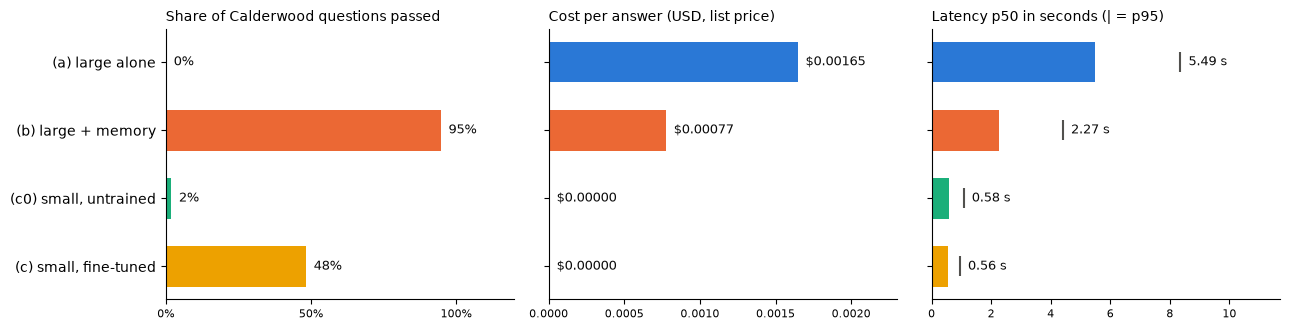

In [24]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # one colour per set-up, in a fixed order
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
panels = [("passed (Calderwood 56)", "Share of Calderwood questions passed", "{:.0%}"),
          ("cost_per_answer", "Cost per answer (USD, list price)", "${:.5f}"),
          ("p50_s", "Latency p50 in seconds (| = p95)", "{:.2f} s")]
for ax, (column, title, fmt) in zip(axes, panels):
    values = board[column].values
    ends = np.maximum(values, board["p95_s"].values) if column == "p50_s" else values   # labels go past the p95 mark
    ax.barh(range(len(SETUPS)), values, color=COLOURS, height=0.6)
    if column == "p50_s":
        ax.scatter(board["p95_s"], range(len(SETUPS)), marker="|", s=200, color="#52514e", zorder=3)
    for i, (v, end) in enumerate(zip(values, ends)):
        ax.text(end, i, "  " + fmt.format(v), va="center", fontsize=9, color="#0b0b0b")
    ax.set_title(title, fontsize=10, loc="left"); ax.set_xlim(0, (ends.max() or 1) * 1.4)
    ax.spines[["top", "right"]].set_visible(False); ax.tick_params(axis="x", labelsize=8)
axes[0].set_yticks(range(len(SETUPS)), SETUPS); axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.2); axes[0].set_xticks([0, 0.5, 1]); axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout(); plt.show()

**How to read the result.** Read the panels left to right: (b) is the only
set-up that is right most of the time (95%); it costs about half as much per
answer as (a) and takes less than half as long. The trained small model (c)
costs nothing per call and answers in about half a second at p50 and under a
second at p95, but is right on 48% of Calderwood's questions. Nothing here is
best on all three measures, which is the case for using more than one model.

> ### 📌 Key Takeaways
> - Read quality per category, not only overall: the prior-knowledge row is where forgetting shows.
> - The per-answer cost of a local model is $0 and the fixed costs are not; both belong on the slide.
> - Latency is a distribution: report p95 as well as p50.

# Part 6 · Preference pairs and routing

The comparison suggests using both models rather than choosing one. This part
explains what notebook 01's preference pairs would add if the small model were
trained on them, and then simulates a router on the answers already recorded,
with no further model calls.

## 6.1 · Preference pairs, and why these ones wait

A preference pair is a prompt, a *chosen* answer and a *rejected* one.
**Direct preference optimisation (DPO)** trains on them directly: it raises
the probability the model gives the chosen answer relative to the rejected
one, measured against a frozen copy of the model before training (the
*reference model*), so the model moves towards the preferred behaviour
without drifting far from what it already does. No reward model and no
sampling loop are needed; libraries such as TRL implement it in a few lines,
and this notebook doesn't need to run it to see whether these pairs are the
right ones.

They aren't, yet, for two reasons the recorded answers show. First, every
*rejected* answer in notebook 01's pairs is Ada's honest *"I can't find
that"*. Second, DPO works best on the model's **own** mistakes (*on-policy*
pairs), and a model's mistakes depend on the model. The next cell counts how
each set-up fails: by declining to answer, or by answering wrongly.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `DECLINES` | Regular expression | Phrases that decline to answer: *"I don't know"*, *"I can't find"*, *"not able to"*, and so on, matched after curly apostrophes are straightened | A crude test, and an inspectable one |
| `failures` | Data | Failed Calderwood answers per set-up, split into declined and answered wrongly | Which kind of rejected answer each model would need |

In [25]:
DECLINES = re.compile(r"don't know|do not know|can't find|cannot find|not sure|unable to|not able to|"
                      r"don't have (?:any |specific |access)|do not have (?:any |specific |access)|no information|"
                      r"isn't something i|not familiar|can't confirm|cannot confirm|check with", re.I)
failed = results[(results.category != "prior_knowledge") & ~results.passed].copy()
failed["kind"] = np.where(failed.answer.str.replace("’", "'").str.contains(DECLINES), "declined", "answered wrongly")
failures = failed.pivot_table(index="setup", columns="kind", values="id", aggfunc="count", fill_value=0)
print(failures.reindex(SETUPS, fill_value=0).to_string())
print("\npreference pair:", json.dumps({k: preference[0][k] for k in ("chosen", "rejected")}, ensure_ascii=False))

kind                   answered wrongly  declined
setup                                            
(a) large alone                      28        28
(b) large + memory                    3         0
(c0) small, untrained                55         0
(c) small, fine-tuned                29         0

preference pair: {"chosen": "You can do goodwill up to £250 yourself, out of the GDR.", "rejected": "I can't find that in the knowledge base. Can anyone on the desk confirm?"}


**How to read the result.**

- **The large model alone fails by declining half the time**: 28 of its 56
  Calderwood failures decline, and 28 give a wrong answer, some of them a
  general insurance meaning of the acronym (PCL as *Premium Credit Limited*).
- **The small models never decline.** All 55 of the untrained model's failures
  and all 29 of the trained model's are answers, mostly confident ones.
- **(b)'s three failures count as answered wrongly**, although two of them
  partly decline (*"I don't have a confirmed Calderwood deadline"*) in words
  the expression doesn't list. The test is crude, and inspectable, which is the
  trade.

So notebook 01's pairs, whose rejected side is always a decline, describe the
large model's failure, not the small model's. Training the small model with
DPO would need **on-policy** pairs: run it, grade its answers, and pair each
invented answer (*"over £5,000"*) as rejected with the right fact as chosen.
It would also need pairs that teach it to decline what it doesn't know, which
it currently never does.

## 6.2 ⭐ Routing between the models

A router decides, before any model answers, which set-up gets the question.
The obvious design for Calderwood: **send the small model what it was trained
for, and escalate the rest to the large model with memory.** The signal is
one the system already computes, the cosine score of the best memory unit from
3.2: a question close to a memory unit is in the small model's territory; a
question far from every unit is not.

The router is a threshold on that score, so the cell below simulates it at
several thresholds from the answers already recorded: for each, the share of
questions the small model takes, the pass rate, the cost per answer and the
p50 latency. The threshold should then be chosen on a validation set; choosing
it on these 61 questions and quoting the result would be reporting a test
score that the test set was used to tune.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `route(threshold)` | Notebook helper | For each question, takes (c)'s recorded answer if `TOP_SCORE` ≥ threshold, else (b)'s | A router replayed over recorded answers: no new calls |
| `routing` | Data | One row per threshold | The trade-off, read across |

In [26]:
by_setup = {s: results[results.setup == s].set_index("id") for s in SETUPS}


def route(threshold):
    rows = [by_setup["(c) small, fine-tuned" if TOP_SCORE[q["id"]] >= threshold else "(b) large + memory"].loc[q["id"]]
            for q in held_out]
    df = pd.DataFrame(rows)
    return {"threshold": threshold, "to small model": (df.setup == "(c) small, fine-tuned").mean(),
            "passed": df.passed.mean(), "prior knowledge passed": df[df.category == "prior_knowledge"].passed.sum(),
            "cost per answer": df.cost.mean(), "p50 s": df.seconds.median()}


routing = pd.DataFrame([route(t) for t in (1.01, 0.80, 0.75, 0.70, 0.65, 0.60, 0.0)])
print(routing.round({"to small model": 2, "passed": 3, "cost per answer": 6, "p50 s": 2}).to_string(index=False))
print("\nbest-unit score of the prior-knowledge questions:",
      {q["id"]: round(TOP_SCORE[q["id"]], 2) for q in held_out if q["category"] == "prior_knowledge"})

 threshold  to small model  passed  prior knowledge passed  cost per answer  p50 s
      1.01            0.00   0.951                       5         0.000774   2.27
      0.80            0.03   0.934                       5         0.000752   2.27
      0.75            0.13   0.885                       5         0.000673   2.21
      0.70            0.26   0.820                       4         0.000572   2.06
      0.65            0.44   0.754                       3         0.000436   1.94
      0.60            0.56   0.705                       3         0.000358   0.87
      0.00            1.00   0.492                       3         0.000000   0.56

best-unit score of the prior-knowledge questions: {'eval_prior_1': 0.73, 'eval_prior_2': 0.68, 'eval_prior_3': 0.77, 'eval_prior_4': 0.36, 'eval_prior_5': 0.32}


**How to read the result.**

- **Every threshold that sends anything to the small model lowers quality.**
  At 0.75, 13% of questions go to the small model, the pass rate falls from
  0.951 to 0.885 and cost per answer (at the list prices in 2.3) falls 13% to
  $0.000673. At 0.60, 56% go to the small model, the pass rate is 0.705, cost
  per answer is less than half ($0.000358) and the p50 latency drops to
  0.87 s. The router buys cost and latency with quality; it never buys
  quality, because the small model isn't better than (b) in any category.
- **The general questions about IBNR, TPA and LAE look in scope.** Their
  best-unit scores are 0.73, 0.68 and 0.77, because their words are
  Calderwood's acronyms; Fibonacci and Tokyo score 0.36 and 0.32. At a
  threshold of 0.70 two of them go to the small model, which answers with the
  house meaning, and prior knowledge drops from 5 to 4.
- **What a useful router would need is a signal for whether the *small model*
  will be right**, not whether the question is about Calderwood: the
  categories it has proven on a validation set (here only the collisions),
  its own confidence, or a check of its answer against the retrieved unit.
  Each of those can be built and measured the same way, by replaying recorded
  answers.

> ### 📌 Key Takeaways
> - DPO trains on chosen and rejected answers against a frozen reference; it needs pairs of the model's own failures.
> - The traces' rejected answers are all declines; a small model that fails by answering wrongly needs different pairs.
> - A router is a threshold on a signal you already have; pick the threshold on validation data, and watch the questions that look in scope and aren't.

# Part 7 · Wrap-up

## What the numbers do and don't show

**What they show:**

- a strong general model answered none of 56 questions about a company it had
  never seen, and declined on half of them;
- three retrieved memory units made the same model right on 53 of 56, at
  about half the cost per answer and half the latency, because its answers got
  shorter;
- 250 training rows took a 0.6B model from 1 to 27 of the 56, at $0 per call
  and about half a second, with invented numbers among its failures;
- training changed how the small model fails on general questions that share
  Calderwood's acronyms: from made-up meanings to Calderwood's meanings;
- a router built on memory similarity trades quality for cost at every
  threshold with this small model.

**What they don't show:**

- **A benchmark.** 61 questions; one question is 1.6 points. The comparison
  shows directions and rough sizes, not a ranking to quote.
- **A precise judge.** The scoring rule missed a right answer with a hyphen in
  it and credited a lucky list of guesses. It is cheap, stable and strict, and
  it should be read alongside the answers.
- **The small model's ceiling.** It was trained on 250 short rows, mostly
  definitions, and tested on scenario questions in other words. More varied
  training rows (scenarios, numbers in context, two-fact questions) are the
  first lever to pull, before a bigger model.
- **Production costs and latency.** List prices change, the local model's
  fixed costs aren't in the per-answer figure, and a shared 16 GB laptop is not
  a serving machine.
- **Preference training.** The notebook explains DPO and shows which pairs it
  would need; it doesn't run it.

## What's next

**Notebook 04** takes the small model trained here, `models/slm/v1`, into
January 2027, when four of Calderwood's facts change: it detects that the
weights are stale, retrains with replay, gates the new version with a paired
test and regression tests, and rolls it back.

> ### 📌 Key Takeaways
> - Token-space memory made the large model right, cheaper and faster on this desk's questions.
> - The trained small model is fast and free per call, right about half the time, and wrong in the house style.
> - Before routing to a small model, prove where it is reliable; similarity to your data is not that proof.